# HBR with Laplace as inference method

`Laplace` approximates the posterior instead of sampling it like `MCMC`. This notebook shows three things:

1. With the default (non-centered) priors, Laplace shifts the z-scores of women and men in opposite directions.
2. A centered random intercept fixes this.
3. With centered priors, Laplace stays close to MCMC after transfer and extend to new sites.

In [21]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pcntoolkit import HBR, MCMC, Laplace, NormativeModel, NormData, load_fcon1000
from pcntoolkit.math_functions.likelihood import get_default_normal_likelihood
from pcntoolkit.math_functions.prior import make_prior
from pcntoolkit.util.output import Output

# Keep the output clean: no logs, warnings or progress messages
warnings.filterwarnings("ignore")
logging.getLogger("pymc").setLevel(logging.ERROR)
Output.set_show_messages(False)
Output.set_show_warnings(False)

In [ ]:
RV = "EstimatedTotalIntraCranialVol"
ADAPT_SITES = ["AnnArbor_a", "Beijing_Zang"]

fcon = load_fcon1000().sel({"response_vars": [RV]})
adapt_sites, base = fcon.batch_effects_split({"site": ADAPT_SITES}, names=("adapt_sites", "base"))
train, test = base.train_test_split((0.8, 0.2), split_names=("train", "test"))
adapt_train, adapt_test = adapt_sites.train_test_split((0.8, 0.2), split_names=("train", "test"))

In [ ]:
CENTILES = [0.05, 0.25, 0.5, 0.75, 0.95]
STYLE = {"MCMC": dict(color="tab:blue", ls="-"), "Laplace": dict(color="tab:orange", ls="--")}


def likelihood(centered: bool):
    """Default Normal likelihood with a centered or non-centered random intercept."""
    lik = get_default_normal_likelihood()
    lik.mu.intercept = make_prior(
        "intercept_mu",
        random=True,
        centered=centered,
        mu=make_prior(dist_params=(0, 1)),
        sigma=make_prior(dist_name="Gamma", dist_params=(1, 0.5)),
    )
    return lik


def inference_method(name: str):
    if name == "MCMC":
        return MCMC(draws=1000, tune=1000, chains=4, cores=4, progressbar=False)
    return Laplace(progressbar=False)


def fit(centered: bool):
    """Fit MCMC and Laplace on the base sites."""
    models, seconds = {}, {}
    for name in STYLE:
        models[name] = NormativeModel(
            HBR(likelihood=likelihood(centered), inference_method=inference_method(name)),
            save_dir=f"resources/hbr_inference/{'centered' if centered else 'noncentered'}_{name}",
            savemodel=False, saveresults=False, saveplots=False,
        )
        start = time.perf_counter()
        models[name].fit(train)
        seconds[name] = time.perf_counter() - start
    return models, seconds


def adapt(models, method: str):
    """Transfer or extend both models to the new sites."""
    adapt_models, seconds = {}, {}
    for name, model in models.items():
        step = model.transfer if method == "transfer" else model.extend
        start = time.perf_counter()
        adapt_models[name] = step(adapt_train, save_dir=f"resources/hbr_inference/{method}_{name}")
        seconds[name] = time.perf_counter() - start
    return adapt_models, seconds


def centiles(model, ages, site, sex):
    """Centile curves (centile x age) for one site and sex."""
    grid = pd.DataFrame({"age": ages, "site": site, "sex": sex, RV: 1e-6})
    d = NormData.from_dataframe("grid", dataframe=grid, covariates=["age"],
                                response_vars=[RV], batch_effects=["site", "sex"])
    model.compute_centiles(d, centiles=CENTILES)
    return d["centiles"].sel(response_vars=RV).values


def compare(models, seconds, data, site, title):
    """Z-scores of MCMC vs Laplace on `data`, and their centiles at `site`."""
    z = {}
    for name, model in models.items():
        d = data.copy(deep=True)
        model.predict(d)
        z[name] = d["Z"].values.ravel()
    sex = data["batch_effects"].sel(batch_effect_dims="sex").values
    age = data.X.sel(covariates="age").values.ravel()
    y = data.Y.values.ravel()
    ages = np.linspace(*np.percentile(age, [2.5, 97.5]), 100)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for s, color in [("F", "tab:red"), ("M", "tab:green")]:
        axes[0].scatter(z["MCMC"][sex == s], z["Laplace"][sex == s], s=10, alpha=0.6, color=color, label=s)
    axes[0].plot([-4, 4], [-4, 4], "k--", lw=1)
    r = np.corrcoef(z["MCMC"], z["Laplace"])[0, 1]
    axes[0].set(xlabel="Z (MCMC)", ylabel="Z (Laplace)", title=f"Test z-scores, r = {r:.3f}")
    axes[0].legend(title="sex")

    for ax, s in zip(axes[1:], ["F", "M"]):
        ax.scatter(age[sex == s], y[sex == s], s=6, color="grey", alpha=0.4)
        for name in models:
            c = centiles(models[name], ages, site, s)
            for j in range(len(CENTILES)):
                ax.plot(ages, c[j], lw=1.5, **STYLE[name], label=name if j == 0 else None)
        ax.set(xlabel="age", ylabel=RV, title=f"Centiles, sex {s}, site {site}")
        ax.legend()
    fig.suptitle(f"{title}  (fit time: MCMC {seconds['MCMC']:.0f} s, Laplace {seconds['Laplace']:.0f} s)")
    fig.tight_layout()
    plt.show()


BASE_SITE = pd.Series(train["batch_effects"].sel(batch_effect_dims="site").values).mode()[0]

## 1. Default (non-centered) priors

Laplace's z-scores split into two bands, one per sex, and its centiles shift away from MCMC. 

Also we see that Laplace is signifacantly faster than MCMC.

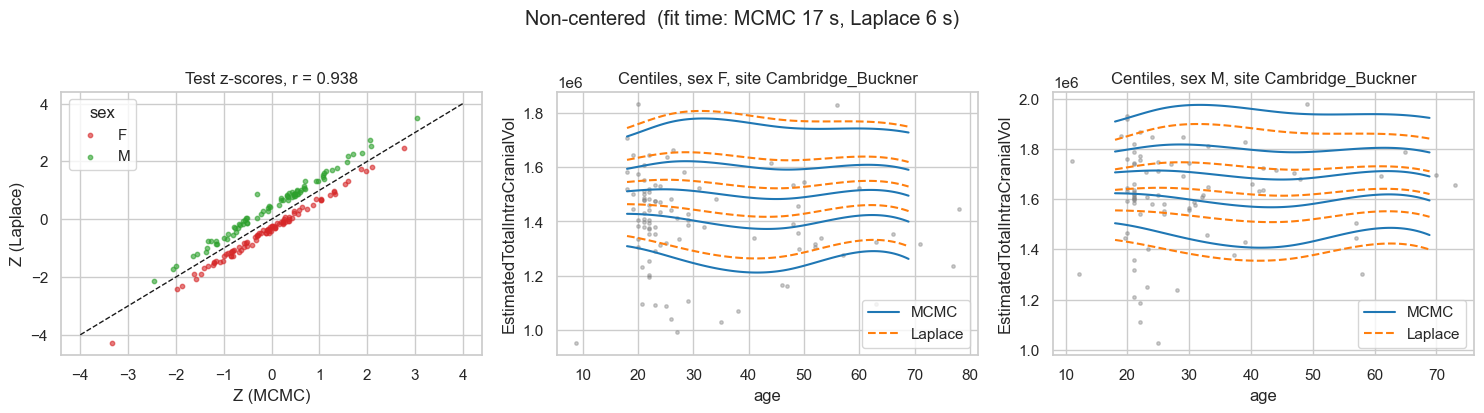

In [24]:
noncentered, seconds = fit(centered=False)
compare(noncentered, seconds, test, BASE_SITE, "Non-centered")

## 2. Centered priors

The only change is `centered=True` on the random intercept. Laplace results are closer to MCMC now.

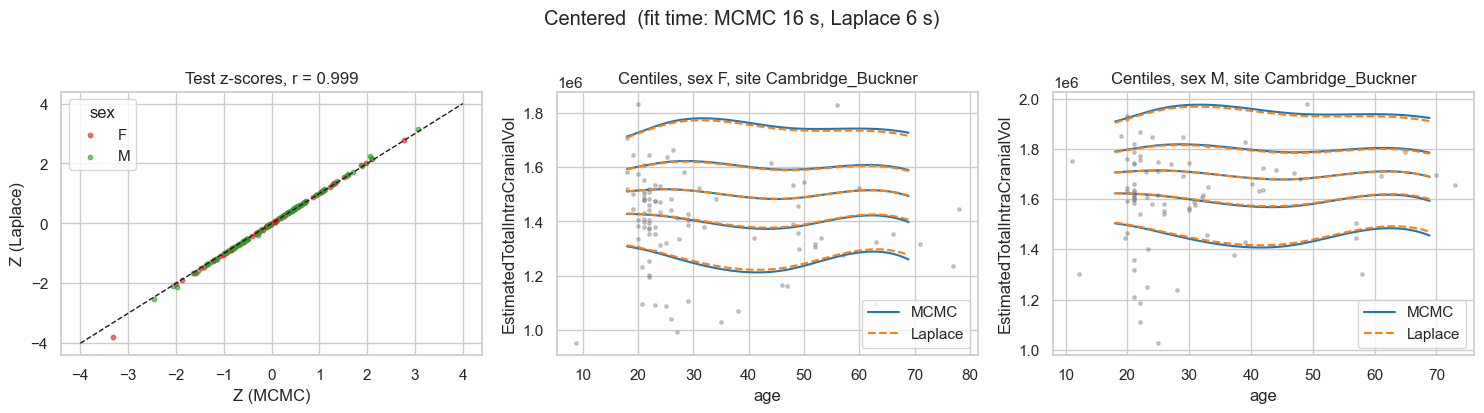

In [25]:
centered, seconds = fit(centered=True)
compare(centered, seconds, test, BASE_SITE, "Centered")

## 3. Transfer to new sites

Starting from the centered models, evaluated on the new sites' test subjects.

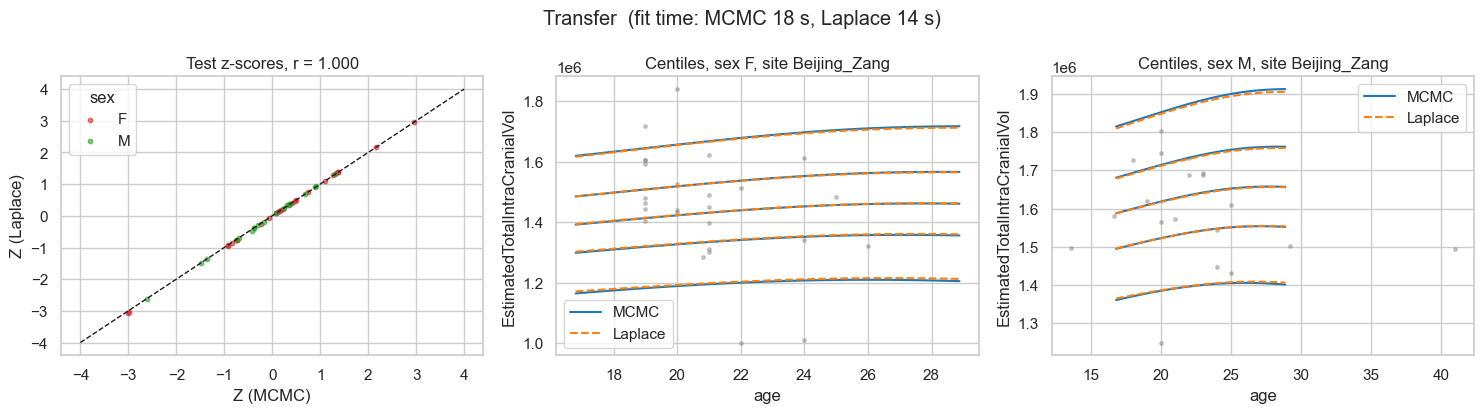

In [ ]:
transferred, seconds = adapt(centered, "transfer")
compare(transferred, seconds, adapt_test, "Beijing_Zang", "Transfer")

## 4. Extend to new sites

Extend has slightly less agreement than transfer. Most likely because each method extends with its own random synthetic data, so the two models are not fitted on the same data.

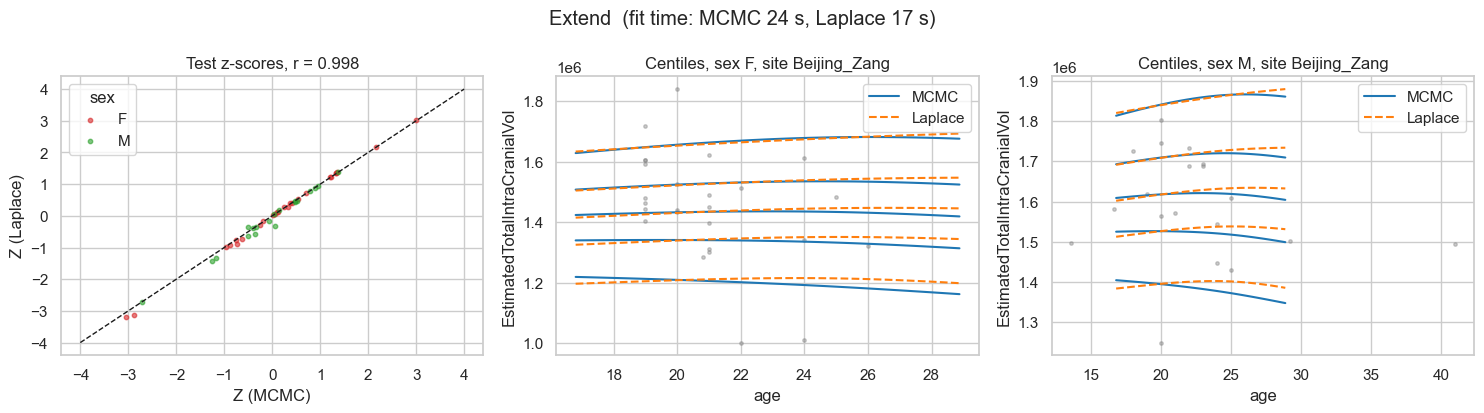

In [ ]:
extended, seconds = adapt(centered, "extend")
compare(extended, seconds, adapt_test, "Beijing_Zang", "Extend")